
- **Stage 1 (no IQ used):** a CNN learns what a 30 s ECG window looks like by playing *fill in the blank*: we hide ~20 % of a window (short chunks) and it must rebuild them from the beats around. It can use the ECG of **all** babies, including the ones without an IQ.
- **Stage 2 (IQ used, tiny model):** the frozen CNN turns every window into 256 numbers (an *embedding*). We average the embeddings per baby and fit a **ridge regression** to IQ with repeated cross-validation by baby.


In [5]:
# Setup 

import math
import os
import sys
import time
from contextlib import nullcontext
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from sklearn.linear_model import RidgeCV
from sklearn.model_selection import KFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from tqdm.auto import tqdm

sys.path.insert(0, str(Path.cwd()))         
import model_0411 as mp

# ------------------------- settings -------------------------
CFG = mp.Config()                            
# CFG.ntfy_topic = "your-ntfy-topic"         # uncomment to get a phone notification when long steps end
OUT_DIR = CFG.segments_dir.parent / "ssl_model"
OUT_DIR.mkdir(parents=True, exist_ok=True)

WINDOW_LEN = CFG.window_len                  # 6000 samples = one 30 s window
BASE_CHANNELS = CFG.base_channels            # keep equal to the pipeline, so encoder.pt fits model_pipeline.py
EMB_DIM = 16 * BASE_CHANNELS                 # numbers describing one window (256 with the default 16)

# stage 1: fill in the blank
N_SPANS, SPAN_LEN = 10, 120                  # hide 10 short chunks of 120 samples (about 20 % of the window)
BATCH = 64
N_STEPS = 4000
LR = 1e-3
VAL_BABY_FRACTION = 0.20                     # babies never used for training stage 1
EVAL_EVERY = 250

# stage 2: embeddings + ridge
MAX_WINDOWS_PER_BABY = 800                   # windows per baby used to compute its embedding (evenly spaced)
CV_FOLDS, CV_REPEATS = 5, 10
N_PERMUTATIONS = 200
RUN_RANDOM_CONTROL = True

SEED = 0
assert WINDOW_LEN == 6000, "the decoder below is built for 6000-sample windows"
mp.set_seed(SEED)
DEVICE = mp.get_device()
USE_AMP = DEVICE.type == "cuda"
print(f"Computing on: {DEVICE}")
print(f"Results will be saved in: {OUT_DIR}")


Computing on: mps
Results will be saved in: /Users/hakim/FISE3/TSE/PRI/FSIQ-from-ECG/data/ssl_model


In [6]:
# data

index = pd.read_csv(CFG.segments_dir / "index.csv")
iq = mp.load_iq(CFG)                                   # {baby id: IQ}

files = {}                                             # baby id -> [(path, number of windows), ...]
for baby_id, rel_paths in index.groupby("id")["chemin"]:
    files[int(baby_id)] = []
    for rel in rel_paths:
        path = mp.resolve_path(rel, CFG.segments_dir)
        shape = np.load(path, mmap_mode="r").shape
        assert len(shape) == 2 and shape[1] == WINDOW_LEN, f"{path.name}: unexpected shape {shape}"
        files[int(baby_id)].append((path, shape[0]))

all_ids = sorted(files)
labeled_ids = [i for i in all_ids if i in iq]
n_windows = {i: sum(n for _, n in files[i]) for i in all_ids}
counts = np.array(list(n_windows.values()))
total = int(counts.sum())

print(f"{len(all_ids)} babies have an ECG: {len(labeled_ids)} with an IQ, {len(all_ids) - len(labeled_ids)} without.")
print(f"Together: {total:,} windows of 30 s = {total * 30 / 3600:,.0f} hours of ECG.")
print(f"A baby has between {counts.min():,} and {counts.max():,} windows (median {int(np.median(counts)):,}).")

IQ (Note composite - QIT): 195 babies with a value, 107 without
294 babies have an ECG: 191 with an IQ, 103 without.
Together: 645,342 windows of 30 s = 5,378 hours of ECG.
A baby has between 354 and 2,832 windows (median 2,124).


In [7]:
# STAGE 1 : Setup

def prep(x):
    """z-score one window. Returns None for a broken window (NaN or flat line)."""
    if not np.isfinite(x).all():
        return None
    sd = x.std()
    if sd < 1e-6:
        return None
    return ((x - x.mean()) / sd).astype(np.float32)


class WindowSampler:
    """Draws random 30 s windows straight from the .npy files (memory-mapped, so little RAM is used)."""

    def __init__(self, ids):
        self.items = [(p, n) for i in ids for p, n in files[i]]
        w = np.array([n for _, n in self.items], dtype=float)
        self.p = w / w.sum()
        self.maps = {}

    def _array(self, path):
        if path not in self.maps:
            self.maps[path] = np.load(path, mmap_mode="r")
        return self.maps[path]

    def batch(self, size, rng):
        out = []
        while len(out) < size:
            path, n = self.items[rng.choice(len(self.items), p=self.p)]
            x = prep(np.asarray(self._array(path)[rng.integers(n)], dtype=np.float32))
            if x is not None:
                out.append(x)
        return torch.from_numpy(np.stack(out))


rng = np.random.default_rng(SEED)
val_ids = set(rng.choice(all_ids, size=max(1, round(VAL_BABY_FRACTION * len(all_ids))), replace=False).tolist())
train_sampler = WindowSampler([i for i in all_ids if i not in val_ids])
val_sampler = WindowSampler(sorted(val_ids))
print(f"Stage 1 trains on {len(all_ids) - len(val_ids)} babies and is checked on {len(val_ids)} other babies it never sees.")


def make_mask(batch_size, generator=None):
    """True where the signal is hidden: N_SPANS random chunks of SPAN_LEN samples per window."""
    starts = torch.randint(0, WINDOW_LEN - SPAN_LEN, (batch_size, N_SPANS, 1), generator=generator)
    pos = torch.arange(WINDOW_LEN).view(1, 1, -1)
    return ((pos >= starts) & (pos < starts + SPAN_LEN)).any(1)


def window_features(encoder, x):
    """x: (batch, 6000). Returns the feature map (batch, 8c, ~188) and the pooled embedding (batch, 16c).
    The embedding = average + maximum over time of the feature map (the final Linear layer of ResNet1D is not used)."""
    fmap = encoder.blocks(encoder.stem(x.unsqueeze(1)))
    return fmap, torch.cat([fmap.mean(-1), fmap.amax(-1)], dim=1)


class MaskedAutoencoder(nn.Module):
    """encoder: window -> feature map (still has a time axis, so it knows WHERE things are).
    decoder: feature map -> rebuilt window. The hidden parts must be guessed from the beats around them."""

    def __init__(self):
        super().__init__()
        self.encoder = mp.ResNet1D(BASE_CHANNELS, 128)     # same CNN as the pipeline
        c = 8 * BASE_CHANNELS

        def up(c_in, c_out, size):
            return nn.Sequential(nn.Upsample(size=size), nn.Conv1d(c_in, c_out, 7, padding=3),
                                 nn.GroupNorm(8, c_out), nn.GELU())

        self.decoder = nn.Sequential(up(c, c, 375), up(c, c // 2, 750), up(c // 2, c // 4, 1500),
                                     up(c // 4, c // 4, 3000), up(c // 4, 8, 6000),
                                     nn.Conv1d(8, 1, 7, padding=3))

    def forward(self, x):                                  # x: (batch, 6000), hidden chunks set to 0
        fmap, emb = window_features(self.encoder, x)
        return self.decoder(fmap).squeeze(1), emb


def reconstruction_loss(recon, x, mask):
    """Error on the hidden parts (what we care about) + a small weight on the visible parts."""
    err = (recon - x) ** 2
    hidden = (err * mask).sum() / mask.sum().clamp(min=1)
    visible = (err * (~mask)).sum() / (~mask).sum().clamp(min=1)
    return hidden + 0.2 * visible, hidden


model = MaskedAutoencoder().to(DEVICE)
n_enc = sum(p.numel() for p in model.encoder.parameters())
print(f"Encoder: {n_enc:,} weights | decoder: {sum(p.numel() for p in model.parameters()) - n_enc:,} weights")
print("Reading guide: the error is measured on the hidden parts; 1.00 means 'no better than drawing a flat line'.")

Stage 1 trains on 235 babies and is checked on 59 other babies it never sees.
Encoder: 274,704 weights | decoder: 196,177 weights
Reading guide: the error is measured on the hidden parts; 1.00 means 'no better than drawing a flat line'.


In [8]:
# Stage 1 : Training
amp = (lambda: torch.autocast("cuda", dtype=torch.float16)) if USE_AMP else (lambda: nullcontext())
opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-2)
warmup = min(200, N_STEPS // 10)
sched = torch.optim.lr_scheduler.LambdaLR(
    opt, lambda s: min(1.0, (s + 1) / warmup) * 0.5 * (1 + math.cos(math.pi * min(1.0, s / N_STEPS))))
scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)


@torch.no_grad()
def validate(n_batches=8):
    model.eval()
    g, r = torch.Generator().manual_seed(123), np.random.default_rng(123)    # same windows/masks every time
    errs = []
    for _ in range(n_batches):
        x = val_sampler.batch(BATCH, r).to(DEVICE)
        mask = make_mask(BATCH, g).to(DEVICE)
        with amp():
            recon, _ = model(x.masked_fill(mask, 0.0))
        errs.append(reconstruction_loss(recon.float(), x, mask)[1].item())
    model.train()
    return float(np.mean(errs))


train_curve, val_curve = [], []
run_loss, t0 = [], time.time()
model.train()
pbar = tqdm(range(1, N_STEPS + 1), desc="Stage 1")
for step in pbar:
    x = train_sampler.batch(BATCH, rng).to(DEVICE)
    mask = make_mask(BATCH).to(DEVICE)
    with amp():
        recon, _ = model(x.masked_fill(mask, 0.0))
    loss, hidden = reconstruction_loss(recon.float(), x, mask)
    opt.zero_grad(set_to_none=True)
    scaler.scale(loss).backward()
    scaler.unscale_(opt)
    nn.utils.clip_grad_norm_(model.parameters(), 1.0)
    scaler.step(opt)
    scaler.update()
    sched.step()
    if step % 5 == 0:
        run_loss.append(hidden.item())
    if step % EVAL_EVERY == 0 or step == N_STEPS:
        v = validate()
        train_curve.append((step, float(np.mean(run_loss[-10:])) if run_loss else float('nan')))
        val_curve.append((step, v))
        tqdm.write(f"step {step:5d}: error on hidden parts = {train_curve[-1][1]:.2f} (training babies), "
                   f"{v:.2f} (babies never seen)   [1.00 = flat line]")

torch.save(model.encoder.state_dict(), OUT_DIR / "encoder.pt")
final_val = val_curve[-1][1]
minutes = (time.time() - t0) / 60
print(f"\nDone in {minutes:.1f} min. Encoder saved to {OUT_DIR / 'encoder.pt'}")
if final_val < 0.9:
    print(f"Verdict: the CNN learned the structure of the ECG (error {final_val:.2f}, clearly below 1.00).")
elif final_val < 0.99:
    print(f"Verdict: it learned a little (error {final_val:.2f}). Try more steps (N_STEPS) or a smaller SPAN_LEN.")
else:
    print(f"Verdict: it learned almost nothing (error {final_val:.2f}). Check the data (flat/noisy signals?) before going on.")
mp.notify(CFG, "Stage 1 done", f"Reconstruction error on unseen babies: {final_val:.2f} (1.00 = flat line). {minutes:.0f} min.")

Stage 1:   6%|▋         | 252/4000 [00:28<08:27,  7.38it/s]

step   250: error on hidden parts = 0.69 (training babies), 0.70 (babies never seen)   [1.00 = flat line]


Stage 1:  13%|█▎        | 502/4000 [00:50<06:10,  9.45it/s]

step   500: error on hidden parts = 0.55 (training babies), 0.60 (babies never seen)   [1.00 = flat line]


Stage 1:  19%|█▉        | 753/4000 [01:12<05:49,  9.28it/s]

step   750: error on hidden parts = 0.50 (training babies), 0.54 (babies never seen)   [1.00 = flat line]


... (22 outputs left out)

Stage 1:  94%|█████████▍| 3753/4000 [05:30<00:28,  8.77it/s]

step  3750: error on hidden parts = 0.43 (training babies), 0.45 (babies never seen)   [1.00 = flat line]


Stage 1: 100%|██████████| 4000/4000 [05:51<00:00, 11.37it/s]

step  4000: error on hidden parts = 0.43 (training babies), 0.45 (babies never seen)   [1.00 = flat line]

Done in 5.9 min. Encoder saved to /Users/hakim/FISE3/TSE/PRI/FSIQ-from-ECG/data/ssl_model/encoder.pt
Verdict: the CNN learned the structure of the ECG (error 0.45, clearly below 1.00).


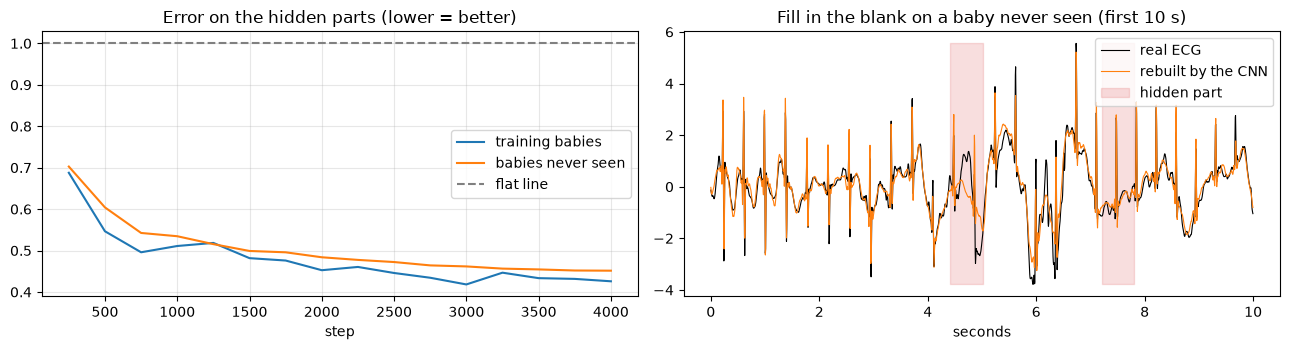

Good sign: the orange curve follows the rhythm (peak positions) inside the red zones.
Where the rhythm is irregular, the rebuilt beats are blurrier than the real ones: normal, exact timing is unpredictable.


In [10]:
fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
ax[0].plot(*zip(*train_curve), label="training babies")
ax[0].plot(*zip(*val_curve), label="babies never seen")
ax[0].axhline(1.0, color="gray", ls="--", label="flat line")
ax[0].set(title="Error on the hidden parts (lower = better)", xlabel="step")
ax[0].legend(); ax[0].grid(alpha=0.3)

model.eval()
g, r = torch.Generator().manual_seed(7), np.random.default_rng(7)
x = val_sampler.batch(3, r).to(DEVICE)
mask = make_mask(3, g).to(DEVICE)
with torch.no_grad():
    recon, _ = model(x.masked_fill(mask, 0.0))
x, recon, mask = x[0].cpu().numpy(), recon[0].float().cpu().numpy(), mask[0].cpu().numpy()
t = np.arange(WINDOW_LEN) / CFG.sampling_rate
sl = slice(0, 2000)
ax[1].plot(t[sl], x[sl], color="black", lw=0.8, label="real ECG")
ax[1].plot(t[sl], recon[sl], color="tab:orange", lw=0.8, label="rebuilt by the CNN")
ax[1].fill_between(t[sl], x[sl].min(), x[sl].max(), where=mask[sl], color="tab:red", alpha=0.15, label="hidden part")
ax[1].set(title="Fill in the blank on a baby never seen (first 10 s)", xlabel="seconds")
ax[1].legend(loc="upper right"); fig.tight_layout()
plt.show()
model.train()
print("Good sign: the orange curve follows the rhythm (peak positions) inside the red zones.")
print("Where the rhythm is irregular, the rebuilt beats are blurrier than the real ones: normal, exact timing is unpredictable.")

In [11]:
@torch.no_grad()
def baby_embeddings(encoder, ids, desc):
    encoder.eval()
    rows = {}
    for i in tqdm(ids, desc=desc):
        s, s2, cnt = np.zeros(EMB_DIM), np.zeros(EMB_DIM), 0
        stride = max(1, math.ceil(n_windows[i] / MAX_WINDOWS_PER_BABY))
        for path, n in files[i]:
            arr = np.load(path, mmap_mode="r")
            picked = np.arange(0, n, stride)
            for chunk in np.array_split(picked, max(1, math.ceil(len(picked) / 256))):
                x = np.asarray(arr[chunk], dtype=np.float32)
                x = x[np.isfinite(x).all(1)]
                sd = x.std(1, keepdims=True)
                keep = sd[:, 0] > 1e-6
                x, sd = x[keep], sd[keep]
                if len(x) == 0:
                    continue
                x = (x - x.mean(1, keepdims=True)) / sd
                with amp():
                    _, z = window_features(encoder, torch.from_numpy(x).to(DEVICE))
                z = z.float().cpu().numpy().astype(np.float64)
                s += z.sum(0); s2 += (z ** 2).sum(0); cnt += len(z)
        mean = s / cnt
        std = np.sqrt(np.maximum(s2 / cnt - mean ** 2, 0))
        rows[i] = np.concatenate([mean, std, [cnt]])
    cols = [f"mean_{k}" for k in range(EMB_DIM)] + [f"std_{k}" for k in range(EMB_DIM)] + ["n_windows_used"]
    return pd.DataFrame.from_dict(rows, orient="index", columns=cols)


encoder = model.encoder
emb_pre = baby_embeddings(encoder, all_ids, "Pretrained encoder")
emb_pre.to_csv(OUT_DIR / "baby_embeddings_pretrained.csv")

emb_rand = None
if RUN_RANDOM_CONTROL:
    torch.manual_seed(SEED)
    rand_encoder = mp.ResNet1D(BASE_CHANNELS, 128).to(DEVICE)
    emb_rand = baby_embeddings(rand_encoder, all_ids, "Random encoder (control)")
    emb_rand.to_csv(OUT_DIR / "baby_embeddings_random.csv")

# sanity check: do embeddings differ between babies, or only within a baby over time?
m = emb_pre[[f"mean_{k}" for k in range(EMB_DIM)]].values
w = (emb_pre[[f"std_{k}" for k in range(EMB_DIM)]].values ** 2).mean(0)
between = m.var(0)
share = float(np.mean(between / (between + w + 1e-12)))
print(f"\n{share:.0%} of the variation in the embeddings is between babies; the rest is variation inside one baby over time.")
print("(Higher = windows of the same baby look alike, so a per-baby summary makes sense.)")
mp.notify(CFG, "Embeddings ready", "Stage 2a done. Now run the ridge + permutation cells.")

Random encoder (control): 100%|██████████| 294/294 [00:42<00:00,  6.94it/s]



29% of the variation in the embeddings is between babies; the rest is variation inside one baby over time.
(Higher = windows of the same baby look alike, so a per-baby summary makes sense.)


In [12]:
ids_lab = np.array(labeled_ids)
y = np.array([iq[i] for i in ids_lab])
groups = mp.load_groups(CFG, ids_lab)
unique_groups = np.unique(groups)


def make_model():
    return make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(0, 5, 21)))


def repeated_cv(X, y_, repeats=CV_REPEATS, seed=SEED):
    """Out-of-fold predictions [repeats, n_babies] and the matching 'guess the mean' baseline."""
    preds, base = np.zeros((repeats, len(y_))), np.zeros((repeats, len(y_)))
    for r in range(repeats):
        for g_tr, g_te in KFold(CV_FOLDS, shuffle=True, random_state=seed + r).split(unique_groups):
            te = np.isin(groups, unique_groups[g_te])
            model_ = make_model().fit(X[~te], y_[~te])
            preds[r, te] = model_.predict(X[te])
            base[r, te] = y_[~te].mean()
    return preds, base


def report(name, X):
    preds, base = repeated_cv(X, y)
    final, b = preds.mean(0), base.mean(0)          # one prediction per baby: average over the repeats
    res, res_b = mp.compute_metrics(y, final), mp.compute_metrics(y, b)
    lo, hi = mp.bootstrap_ci(y, final, b, 2000, SEED)["MAE_gain_vs_baseline"]
    gain = res_b["MAE"] - res["MAE"]
    if lo > 0:
        verdict = "clearly better than guessing the mean"
    elif hi < 0:
        verdict = "clearly WORSE than guessing the mean"
    else:
        verdict = "NOT distinguishable from guessing the mean"
    print(f"{name}\n  average error {res['MAE']:.2f} IQ points vs {res_b['MAE']:.2f} for 'guess the mean' "
          f"-> gain {gain:+.2f} points (95% CI {lo:+.2f} to {hi:+.2f}), R2 = {res['R2']:.2f}\n  => {verdict}.\n")
    return {"features": name, "error (IQ pts)": res["MAE"], "guess-the-mean error": res_b["MAE"],
            "gain (IQ pts)": gain, "gain CI low": lo, "gain CI high": hi, "R2": res["R2"], "verdict": verdict}


mean_cols = [f"mean_{k}" for k in range(EMB_DIM)]
all_cols = mean_cols + [f"std_{k}" for k in range(EMB_DIM)]
X_pre = emb_pre.loc[ids_lab]

results = [report("Pretrained encoder, mean only (256 features)", X_pre[mean_cols].values),
           report("Pretrained encoder, mean + std (512 features)  <- main test, decided in advance", X_pre[all_cols].values)]
if emb_rand is not None:
    results.append(report("RANDOM encoder, mean + std (512 features)  <- control", emb_rand.loc[ids_lab][all_cols].values))

summary = pd.DataFrame(results)
summary.to_csv(OUT_DIR / "ridge_results.csv", index=False)
print("Reading guide: if the pretrained encoder is not better than the random one, pretraining added nothing.")

Pretrained encoder, mean only (256 features)
  average error 10.57 IQ points vs 10.55 for 'guess the mean' -> gain -0.02 points (95% CI -0.05 to +0.01), R2 = -0.02
  => NOT distinguishable from guessing the mean.

Pretrained encoder, mean + std (512 features)  <- main test, decided in advance
  average error 10.56 IQ points vs 10.55 for 'guess the mean' -> gain -0.01 points (95% CI -0.18 to +0.15), R2 = -0.03
  => NOT distinguishable from guessing the mean.

RANDOM encoder, mean + std (512 features)  <- control
  average error 10.62 IQ points vs 10.55 for 'guess the mean' -> gain -0.07 points (95% CI -0.21 to +0.06), R2 = -0.03
  => NOT distinguishable from guessing the mean.

Reading guide: if the pretrained encoder is not better than the random one, pretraining added nothing.


Permutations: 100%|██████████| 200/200 [00:06<00:00, 30.38it/s]


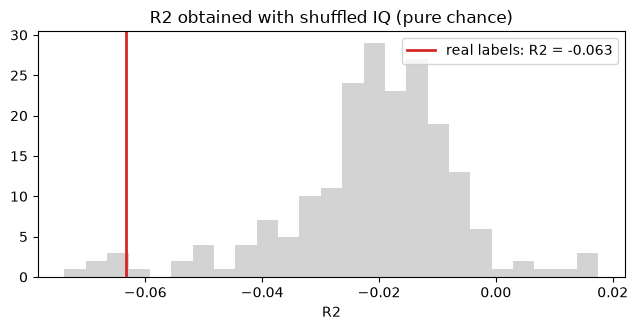

Real IQ: R2 = -0.063.
Shuffled IQ (chance): R2 between -0.063 and 0.005 in 95% of cases.
p-value = 0.975
=> Nothing above chance: with these data, this ECG representation does not predict IQ.


In [13]:
def r2(y_, p):
    return 1 - np.sum((y_ - p) ** 2) / np.sum((y_ - y_.mean()) ** 2)


def stat(X, y_):
    preds, _ = repeated_cv(X, y_, repeats=2)
    return float(np.mean([r2(y_, p) for p in preds]))


X_main = X_pre[all_cols].values                      # the main test announced above (no cherry-picking)
observed = stat(X_main, y)
prng = np.random.default_rng(SEED)
null = np.array([stat(X_main, prng.permutation(y)) for _ in tqdm(range(N_PERMUTATIONS), desc="Permutations")])
p_value = (1 + int((null >= observed).sum())) / (1 + N_PERMUTATIONS)

plt.figure(figsize=(6.5, 3.4))
plt.hist(null, bins=25, color="lightgray")
plt.axvline(observed, color="tab:red", lw=2, label=f"real labels: R2 = {observed:.3f}")
plt.title("R2 obtained with shuffled IQ (pure chance)"); plt.xlabel("R2"); plt.legend(); plt.tight_layout(); plt.show()

lo, hi = np.percentile(null, [2.5, 97.5])
print(f"Real IQ: R2 = {observed:.3f}.")
print(f"Shuffled IQ (chance): R2 between {lo:.3f} and {hi:.3f} in 95% of cases.")
print(f"p-value = {p_value:.3f}")
if p_value < 0.05:
    print("=> The ECG embeddings carry information about IQ that is unlikely to be chance (still confirm on other splits/data).")
else:
    print("=> Nothing above chance: with these data, this ECG representation does not predict IQ.")

In [14]:
print(summary[["features", "error (IQ pts)", "guess-the-mean error", "gain (IQ pts)", "R2"]].round(2).to_string(index=False))
print(f"\nPermutation test on the main test: p = {p_value:.3f}")
msg = (f"Pretrained: gain {summary.loc[1, 'gain (IQ pts)']:+.2f} pts "
       f"[{summary.loc[1, 'gain CI low']:+.2f}, {summary.loc[1, 'gain CI high']:+.2f}], p={p_value:.3f}")
if emb_rand is not None:
    msg += f" | random-encoder gain {summary.loc[2, 'gain (IQ pts)']:+.2f}"
print(msg)
mp.notify(CFG, "Notebook finished", msg)

                                                                       features  error (IQ pts)  guess-the-mean error  gain (IQ pts)    R2
                                   Pretrained encoder, mean only (256 features)           10.57                 10.55          -0.02 -0.02
Pretrained encoder, mean + std (512 features)  <- main test, decided in advance           10.56                 10.55          -0.01 -0.03
                          RANDOM encoder, mean + std (512 features)  <- control           10.62                 10.55          -0.07 -0.03

Permutation test on the main test: p = 0.975
Pretrained: gain -0.01 pts [-0.18, +0.15], p=0.975 | random-encoder gain -0.07
